# Exploration of Fermi galactic model

In [1]:
from astropy.io import fits
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt

plt.rcParams['figure.dpi'] = 400
plt.rcParams['savefig.dpi'] = 400

dirDir = "/home/users/l/lebrun/"
dataDir = dirDir + "data/"
figPath = dirDir + "figures/fermiGIEM/"
resultPath = dirDir + "results/"

filename = "gll_iem_v07.fits"
filePath = dataDir + filename
hdul = fits.open(filePath)
hdul.info()

Filename: /home/users/l/lebrun/data/gll_iem_v07.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU      24   (2880, 1441, 28)   float32   
  1  ENERGIES      1 BinTableHDU     12   28R x 1C   [D]   


In [2]:
fit_threshold = 98

Resolution : 8 pixels / degree

In [3]:
import numpy as np

data_cube = hdul[0].data  
data_cube = np.array(data_cube, dtype=np.float64)
data_cube *= 1000 # COnvert to GeV ^-1
print("Shape:", data_cube.shape)

Shape: (28, 1441, 2880)


Sepctrum  :30 Energy bins

In [4]:
energy_table = hdul['ENERGIES'].data
energies_mev = energy_table['ENERGY']  # in MeV
energies_gev = energies_mev / 1e3
print(energies_gev)

sep = energies_gev[1:]/energies_gev[:-1]
print(sep)

[5.00000000e-02 6.49828300e-02 8.44553639e-02 1.09762971e-01
 1.42654170e-01 1.85401433e-01 2.40958196e-01 3.13162910e-01
 4.07004243e-01 5.28965751e-01 6.87473830e-01 8.93479900e-01
 1.16121705e+00 1.50918340e+00 1.96142017e+00 2.54917267e+00
 3.31304908e+00 4.30582611e+00 7.27300221e+00 1.22848810e+01
 2.07504819e+01 3.50497899e+01 5.92028552e+01 9.99999737e+01
 1.68910683e+02 2.85308264e+02 4.81916266e+02 8.14008272e+02]
[1.2996566  1.2996566  1.2996566  1.2996566  1.2996566  1.2996566
 1.2996566  1.2996566  1.2996566  1.2996566  1.2996566  1.2996566
 1.2996566  1.2996566  1.2996566  1.2996566  1.2996566  1.68910728
 1.68910728 1.68910728 1.68910728 1.68910728 1.68910728 1.68910728
 1.68910728 1.68910728 1.68910728]


In [5]:
def plot_map(lon_centers, lat_centers, map, title="", label="", output_name="", logNorm = False, figPath = None):
    """ Plot the exposure map in Mollweide projection.  
    Args:
        lon_centers (np.ndarray): 1D array of galactic longitudes in radians.
        lat_centers (np.ndarray): 1D array of galactic latitudes in radians.
        map (np.ndarray): 2D array of exposure values.
        figPath (str, optional): Path to save the figure. If None, the figure is shown.
    """

    # Convert your 1D radian lon/lat centers into 2D grid
    lon_grid, lat_grid = np.meshgrid(lon_centers, lat_centers, indexing='ij')

    # Convert to Mollweide's expected range: [-π, π] in lon, [-π/2, π/2] in lat
    lon_plot = lon_grid.T  # Transpose to match shape
    lat_plot = lat_grid.T
    map_plot = map.T  # Transpose as well to match pcolormesh layout

    # Plot
    fig = plt.figure(figsize=(10, 5))
    ax = fig.add_subplot(111, projection='mollweide')

    # Plot with pcolormesh (lon, lat must be in radians)
    if logNorm :
        norm = mcolors.LogNorm()  # Use logarithmic normalization for color scale
    else : 
        norm = None
    mesh = ax.pcolormesh(lon_plot, lat_plot, map_plot, cmap='viridis', shading='auto', norm=norm)

    # Final touches
    fig.colorbar(mesh, ax=ax, label=label)
    ax.set_title(title)
    tick_labels = np.array([150, 120, 90, 60, 30, 0, -30, -60, -90, -120, -150])
    ax.set_xticklabels(tick_labels)
    ax.xaxis.set_tick_params(labelcolor="white")
    ax.set_xlabel('Galactic Longitude [deg]')
    ax.set_ylabel('Galactic Latitude [deg]')
    ax.set_facecolor('black')
    ax.grid(True)

    if figPath :
        figName = figPath + output_name
        fig.savefig(figName)

    return fig


def plot_counts_map(lon_centers, lat_centers, counts_map, energy = None, figPath = None):

    title = "γ-rays Counts, 9 years"
    label = "Counts"
    output_name = "CountMap"
    if energy:
        title += f" | Energy : {energy} GeV"
        output_name += f"-{energy}"
    output_name += ".png"

    return plot_map(lon_centers, lat_centers, counts_map, title, label, output_name, True, figPath)

def plot_flux_map(lon_centers, lat_centers, flux_map, energy=None, figPath=None):
    title = "γ-rays Flux, 9 years"
    label = "Counts/Exposure [cm⁻2 s-1]"
    output_name = "FluxMap"
    if energy:
        title += f" | Energy : {energy} GeV"
        output_name += f"-{energy}"
    output_name += ".png"
    return plot_map(lon_centers, lat_centers, flux_map, title, label, output_name, True, figPath)


def plot_exposure_map(lon_centers, lat_centers, exposure_map, energy, figPath = None):
    """ Plot the exposure map in Mollweide projection.  
    Args:
        lon_centers (np.ndarray): 1D array of galactic longitudes in radians.
        lat_centers (np.ndarray): 1D array of galactic latitudes in radians.
        exposure_map (np.ndarray): 2D array of exposure values.
        figPath (str, optional): Path to save the figure. If None, the figure is shown.
    """

    title = f'Exposure Map ({energy} GeV)'
    label = 'Exposure [cm² sr s]'
    output_name = f"{energy}GeV_exposure_sum.png"

    return plot_map(lon_centers, lat_centers, exposure_map, title, label, output_name, figPath)

In [6]:
header = hdul[0].header
header2 = hdul[1].header
print(header)
print(header2)

SIMPLE  =                    T / conforms to FITS standard                      BITPIX  =                  -32 / array data type                                NAXIS   =                    3 / number of array dimensions                     NAXIS1  =                 2880                                                  NAXIS2  =                 1441                                                  NAXIS3  =                   28                                                  EXTEND  =                    T                                                  CRVAL1  =                    0                                                  CDELT1  =               -0.125                                                  CRPIX1  =               1440.5                                                  CTYPE1  = 'GLON-CAR'                                                            CUNIT1  = 'deg     '                                                            CRVAL2  =                    0          

In [7]:

energy_axis = hdul[0].header['NAXIS3']
print("Energy axis length:", energy_axis)

energies = np.array(hdul[1].data, dtype=np.float64)
print(type(energies[0]))
print("Energies shape:", energies.shape)
print("Energies:", energies)
log_ratios = np.log10(energies[1:] / energies[:-1])
print(log_ratios)
print("Mean log step:", np.mean(log_ratios))

Energy axis length: 28
<class 'numpy.float64'>
Energies shape: (28,)
Energies: [5.00000000e+01 6.49828300e+01 8.44553639e+01 1.09762971e+02
 1.42654170e+02 1.85401433e+02 2.40958196e+02 3.13162910e+02
 4.07004243e+02 5.28965751e+02 6.87473830e+02 8.93479900e+02
 1.16121705e+03 1.50918340e+03 1.96142017e+03 2.54917267e+03
 3.31304908e+03 4.30582611e+03 7.27300221e+03 1.22848810e+04
 2.07504819e+04 3.50497899e+04 5.92028552e+04 9.99999737e+04
 1.68910683e+05 2.85308264e+05 4.81916266e+05 8.14008272e+05]
[0.11382862 0.11382862 0.11382862 0.11382862 0.11382862 0.11382862
 0.11382862 0.11382862 0.11382862 0.11382862 0.11382862 0.11382862
 0.11382862 0.11382862 0.11382862 0.11382862 0.11382862 0.22765723
 0.22765723 0.22765723 0.22765723 0.22765723 0.22765723 0.22765723
 0.22765723 0.22765723 0.22765723]
Mean log step: 0.1559873634813129


In [8]:
# Longitude info
n_lon = header['NAXIS1']
crval1 = header['CRVAL1']  # Reference value (center)
cdelt1 = header['CDELT1']  # Step size
crpix1 = header['CRPIX1']  # Reference pixel

# Latitude info
n_lat = header['NAXIS2']
crval2 = header['CRVAL2']
cdelt2 = header['CDELT2']
crpix2 = header['CRPIX2']

# Compute pixel centers in degrees
lon_centers_deg = crval1 + (np.arange(n_lon) + 1 - crpix1) * cdelt1
lat_centers_deg = crval2 + (np.arange(n_lat) + 1 - crpix2) * cdelt2

# Convert to radians
lon_centers_rad = np.radians(lon_centers_deg)
lat_centers_rad = np.radians(lat_centers_deg)

print("Longitudes : ", lon_centers_rad)
print("Latitudes : ", lat_centers_rad)

Longitudes :  [ 3.14050182  3.13832016  3.1361385  ... -3.1361385  -3.13832016
 -3.14050182]
Latitudes :  [-1.57079633 -1.56861467 -1.566433   ...  1.566433    1.56861467
  1.57079633]


In [9]:
energy_table = hdul['ENERGIES'].data
energies_gev = energy_table['ENERGY'] / 1e3  # MeV → GeV
idx = np.abs(energies_gev - 1.0).argmin()
energy_selected = energies_gev[idx]

sky_slice = data_cube[idx]  # shape: (lat, lon) or (lon, lat) depending on FITS
sky_slice = sky_slice.T
print(sky_slice.shape)

print(lon_centers_rad.shape)
print(lat_centers_rad.shape)

print(f"Longitude centers span from {np.min(lon_centers_deg)} to {np.max(lon_centers_deg)} deg ")
print(f"Latitude centers span from {np.min(lat_centers_deg)} to {np.max(lat_centers_deg)} deg")
print(f"Longitude centers span from {np.min(lon_centers_rad)} to {np.max(lon_centers_rad)} rad ")
print(f"Latitude centers span from {np.min(lat_centers_rad)} to {np.max(lat_centers_rad)} rad")
print(np.pi/2)

(2880, 1441)
(2880,)
(1441,)
Longitude centers span from -179.9375 to 179.9375 deg 
Latitude centers span from -90.0 to 90.0 deg
Longitude centers span from -3.140501822807297 to 3.140501822807297 rad 
Latitude centers span from -1.5707963267948966 to 1.5707963267948966 rad
1.5707963267948966


In [ ]:
print(f"Energy centers span from {np.min(energies_gev)} to {np.max(energies_gev)} GeV")
# Compute the logarithmic spacing factor
log_spacing = np.log(energies_gev[1] / energies_gev[0])

r = np.exp(log_spacing)
edges = energies_gev * np.sqrt(1 / r)
edges = np.append(edges, energies_gev[-1] * np.sqrt(r))

# Check results
print(f"Recovered {len(edges)-1} bin edges:")
print(edges)

Energy centers span from 0.049999999999999996 to 814.008272175696 GeV
Recovered 28 bin edges:
[4.38586941e-02 5.70012412e-02 7.40820394e-02 9.62812114e-02
 1.25132512e-01 1.62629295e-01 2.11362236e-01 2.74698326e-01
 3.57013492e-01 4.63994941e-01 6.03034087e-01 7.83737232e-01
 1.01858927e+00 1.32381626e+00 1.72050654e+00 2.23606768e+00
 2.90612012e+00 3.77695820e+00 6.37968758e+00 1.07759767e+01
 1.82017807e+01 3.07447603e+01 5.19311983e+01 8.77173650e+01
 1.48164040e+02 2.50264958e+02 4.22724362e+02 7.14026796e+02
 9.27989637e+02]


In [ ]:
energy_centers = np.sqrt(energies_gev[:-1] * energies_gev[1:])
print(energy_centers)

[5.70012412e-02 7.40820394e-02 9.62812114e-02 1.25132512e-01
 1.62629295e-01 2.11362236e-01 2.74698326e-01 3.57013492e-01
 4.63994941e-01 6.03034087e-01 7.83737232e-01 1.01858927e+00
 1.32381626e+00 1.72050654e+00 2.23606768e+00 2.90612012e+00
 3.77695820e+00 5.59609532e+00 9.45240533e+00 1.59661266e+01
 2.69685007e+01 4.55526908e+01 7.69433815e+01 1.29965626e+02
 2.19525884e+02 3.70802769e+02 6.26325656e+02]


In [12]:
def plot_sky_slice(energy, data_cube, energies_gev):
    idx = np.abs(energies_gev - energy).argmin()
    energy_selected = energies_gev[idx]

    sky_slice = data_cube[idx]  # shape: (lat, lon) or (lon, lat) depending on FITS
    sky_slice = sky_slice.T

    fig = plot_map(
    -lon_centers_rad,
    lat_centers_rad,
    sky_slice,
    title=f"Fermi galactic background @ {energy_selected:.3f} GeV",
    label="Flux [counts cm² s$^{{-1}}$ sr$^{{-1}}$ GeV$^{{-1}}$]",
    logNorm=True,
    figPath=None  # or None to show
    )
    
    return fig

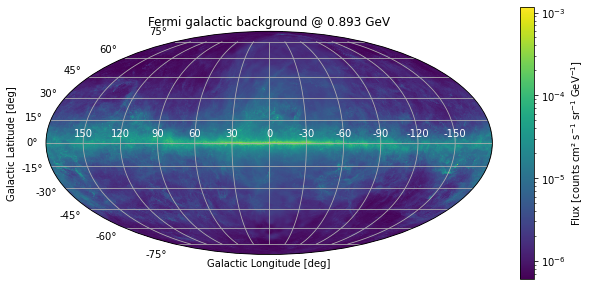

In [13]:
fig = plot_sky_slice(1, data_cube, energies_gev)

### Show spectrum of one pixel

In [ ]:
def plot_pixel_spectrum(x,y):
    spectrum = data_cube[:, y, x]  # shape (28,)

    lon = lon_centers_deg[x]
    lat = lat_centers_deg[y]

    # Select only energies > 1 GeV
    mask = energies_gev > fit_threshold
    x_fit = energies_gev[mask]
    y_fit = spectrum[mask]

    # Fit log(y) = a*log(x) + b → y = exp(b) * x^a
    coeffs = np.polyfit(np.log10(x_fit), np.log10(y_fit), 1)
    a, b = coeffs

    # Plot data and fit
    fig, ax = plt.subplots()
    ax.loglog(energies_gev, spectrum, marker='o', label='Data')
    ax.loglog(x_fit, 10**(a * np.log10(x_fit) + b), label=f'Power law fit: y ∝ x^{a:.2f}')
    ax.set_xlabel("Energy [GeV]")
    ax.set_ylabel("Flux [cm$^{{-2}}$ s$^{{-1}}$ sr$^{{-1}}$ GeV${{-1}}$]")
    ax.set_title(f"Energy spectrum at pixel (lon={lon:.2f}°, lat={lat:.2f}°)")
    ax.grid(True, which="both", ls="--")
    ax.legend()
    return fig, ax
    

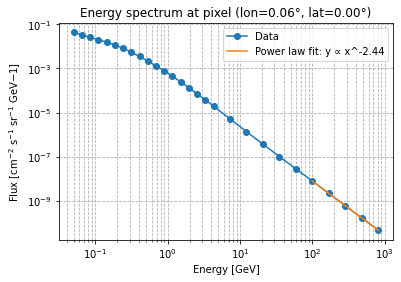

In [15]:
x = 1439
y = 720
fig, ax = plot_pixel_spectrum(x,y)
fig.savefig(figPath + f"pixelSpectrum_{x}_{y}.png")

In [16]:
# Combine the two log-steps (first fine, then coarse)
log_step1 = 0.11382862
log_step2 = 0.22765723

# Determine where the current switch happens
index_switch = 18  # where step increases from 0.1138 → 0.2276
energies_lo = energies_gev[:index_switch + 1]
energies_hi = energies_gev[index_switch + 1:]

# Generate new log-spaced bins from the last value up to 10 TeV
log_E_start = np.log10(energies_gev[-1])  # log10(814)
log_E_end = np.log10(1e4)                 # log10(10,000)

# Continue using the coarse spacing
n_extra_bins = int(np.floor((log_E_end - log_E_start) / log_step2))
log_E_extra = log_E_start + log_step2 * np.arange(1, n_extra_bins + 1)
energies_extra = 10**log_E_extra

# Final extended energy grid
energies_all = np.concatenate([energies_gev, energies_extra])
print(energies_all)

[5.00000000e-02 6.49828300e-02 8.44553639e-02 1.09762971e-01
 1.42654170e-01 1.85401433e-01 2.40958196e-01 3.13162910e-01
 4.07004243e-01 5.28965751e-01 6.87473830e-01 8.93479900e-01
 1.16121705e+00 1.50918340e+00 1.96142017e+00 2.54917267e+00
 3.31304908e+00 4.30582611e+00 7.27300221e+00 1.22848810e+01
 2.07504819e+01 3.50497899e+01 5.92028552e+01 9.99999737e+01
 1.68910683e+02 2.85308264e+02 4.81916266e+02 8.14008272e+02
 1.37494729e+03 2.32243345e+03 3.92283922e+03 6.62609622e+03]


In [17]:
def plot_extended_pixel_spectrum(x, y, energies_gev, data_cube):

    spectrum = data_cube[:, y, x]  # shape (28,)
    
    lon = lon_centers_deg[x]
    lat = lat_centers_deg[y]
    
    # Select only high-energy points for the fit
    mask_data = (energies_gev < 815)
    mask_fit = (energies_gev > fit_threshold) & (energies_gev < 815)
    mask_fit_extra = (energies_gev > fit_threshold)
    x_fit = energies_gev[mask_fit]
    y_fit = spectrum[mask_fit]

    # Fit log(y) = a*log(x) + b
    coeffs = np.polyfit(np.log10(x_fit), np.log10(y_fit), 1)
    a, b = coeffs

    # Evaluate power-law extrapolation
    spectrum_extrap = spectrum[mask_fit_extra]

    # Plot
    fig, ax = plt.subplots()
    ax.loglog(energies_gev[mask_data], spectrum[mask_data], marker='o', label='Data')
    ax.loglog(energies_gev[~mask_data], spectrum[~mask_data], marker='o', label='Extrapolated')
    ax.loglog(energies_gev[mask_fit_extra], spectrum_extrap, '--', color='orange',
               label=f'Power law fit : y ∝ E^{a:.2f}')
    ax.set_xlabel("Energy [GeV]")
    ax.set_ylabel("Flux [cm$^{{-2}}$ s$^{{-1}}$ sr$^{{-1}}$ GeV${{-1}}$]")
    ax.set_title(f"Energy spectrum and fit at pixel (lon={lon:.2f}°, lat={lat:.2f}°)")
    ax.grid(True, which="both", ls="--")
    ax.legend()
    return fig, ax

In [18]:
import numpy as np

nE_old, ny, nx = data_cube.shape

# Only fit where E > 10 GeV
fit_mask = energies_gev > fit_threshold
x_fit = np.log10(energies_gev[fit_mask])  # shape (nE_fit,)

# Prepare X matrix for polyfit: [log(x), 1]
X = np.vstack([x_fit, np.ones_like(x_fit)]).T  # shape (nE_fit, 2)

# Compute pseudo-inverse once
X_pinv = np.linalg.pinv(X)  # shape (2, nE_fit)

# Take log10 of spectrum, reshape: (nE_fit, ny*nx)
Y = np.log10(data_cube[fit_mask].reshape(len(x_fit), -1))  # shape (nE_fit, ny*nx)

# Mask invalid (non-positive) values
valid = np.all(np.isfinite(Y), axis=0)
Y[:, ~valid] = 0  # Avoid NaNs in fit

# Vectorized linear regression: (2, ny*nx)
coeffs = X_pinv @ Y
a, b = coeffs[0], coeffs[1]  # shape (ny*nx,)

# Define log10 energies to extrapolate to (10^4 GeV)
logE_extra = np.arange(np.log10(energies_gev[-1]) + 0.227, np.log10(1e4), 0.227)
energies_extra = 10**logE_extra
nE_extra = len(energies_extra)

# Compute extrapolated log(y): shape (nE_extra, ny*nx)
log_y_extra = np.outer(logE_extra, a) + b  # broadcasting

# Convert to real y, reshape back: (nE_extra, ny, nx)
y_extra = np.power(10.0, log_y_extra).reshape(nE_extra, ny, nx)

# Combine original + extrapolated
energies_all = np.concatenate([energies_gev, energies_extra])
data_cube_extended = np.concatenate([data_cube, y_extra], axis=0)

print(f"[DONE] Vectorized extrapolation complete. Shape: {data_cube_extended.shape}")
print("Saving to file ...")

# Save
np.savez_compressed(resultPath + "giem_extrapolated.npz",
                    data=data_cube_extended,
                    energies=energies_all)

print("GIEM data saved")

[DONE] Vectorized extrapolation complete. Shape: (32, 1441, 2880)
Saving to file ...
GIEM data saved


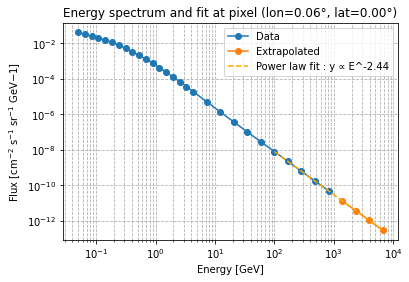

In [19]:
x = 1439
y = 720

fig, ax = plot_extended_pixel_spectrum(x,y, energies_all, data_cube_extended)
fig.savefig(figPath + f"pixelExtraSpectrum_{x}_{y}.png")

In [20]:
print(energies_gev.max())
print(energies_all.max())
print(energies_all)

814.008272175696
6586.107549146351
[5.00000000e-02 6.49828300e-02 8.44553639e-02 1.09762971e-01
 1.42654170e-01 1.85401433e-01 2.40958196e-01 3.13162910e-01
 4.07004243e-01 5.28965751e-01 6.87473830e-01 8.93479900e-01
 1.16121705e+00 1.50918340e+00 1.96142017e+00 2.54917267e+00
 3.31304908e+00 4.30582611e+00 7.27300221e+00 1.22848810e+01
 2.07504819e+01 3.50497899e+01 5.92028552e+01 9.99999737e+01
 1.68910683e+02 2.85308264e+02 4.81916266e+02 8.14008272e+02
 1.37286811e+03 2.31541487e+03 3.90506996e+03 6.58610755e+03]


In [21]:
# for i in range(10):
#     x = np.random.randint(0, 2880)
#     y = np.random.randint(0, 721)
#     plot_extended_pixel_spectrum(x,y, energies_all, data_cube_extended)

/tmp/ipykernel_2879232/2542457412.py:19: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig = plt.figure(figsize=(10, 5))


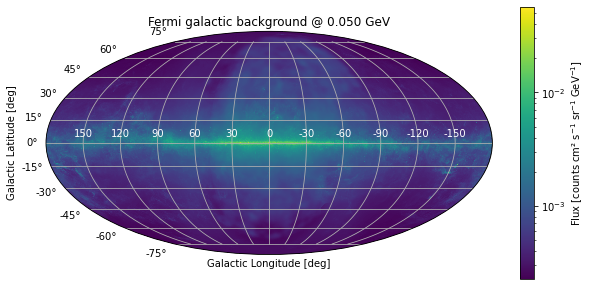

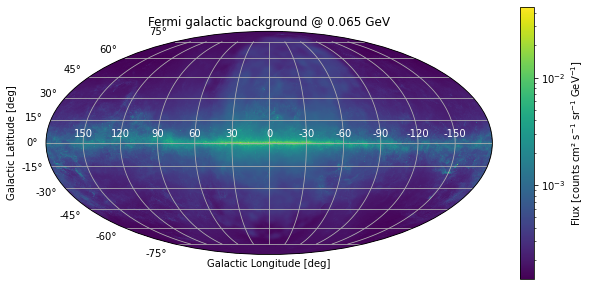

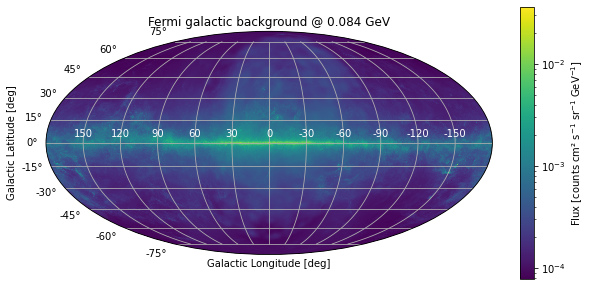

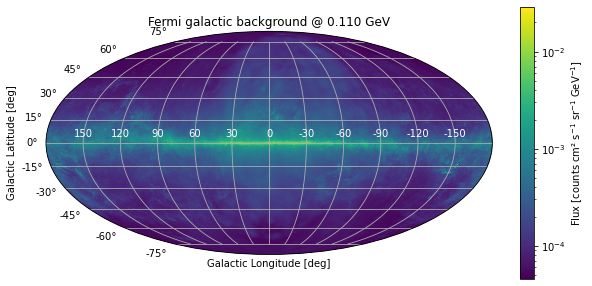

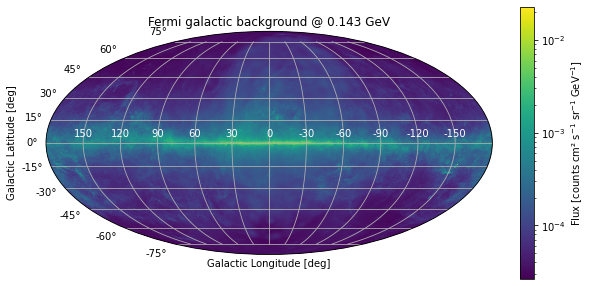

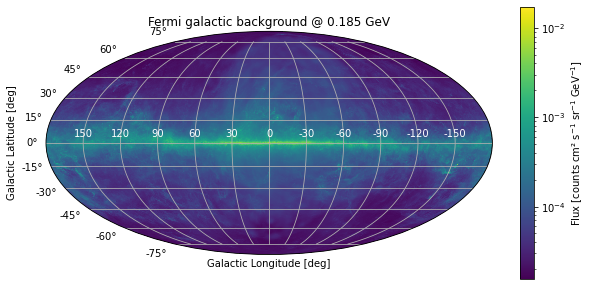

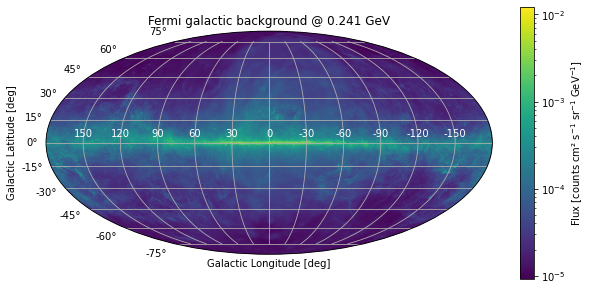

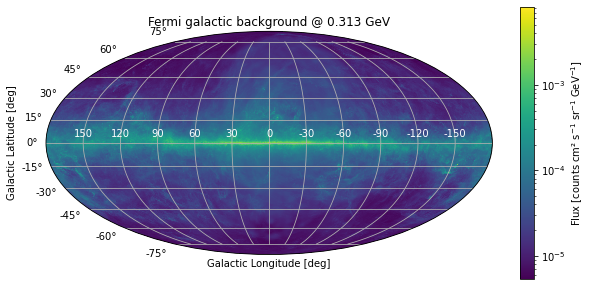

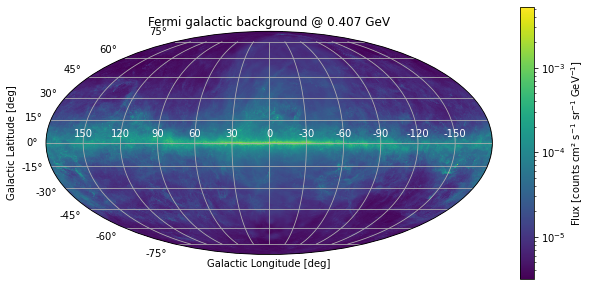

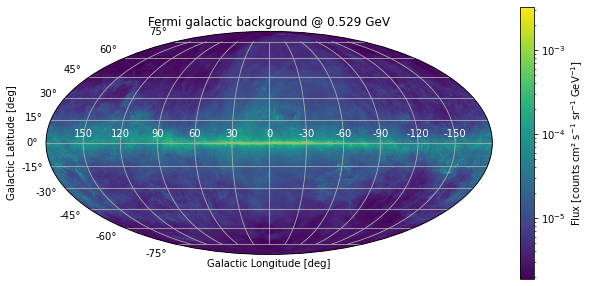

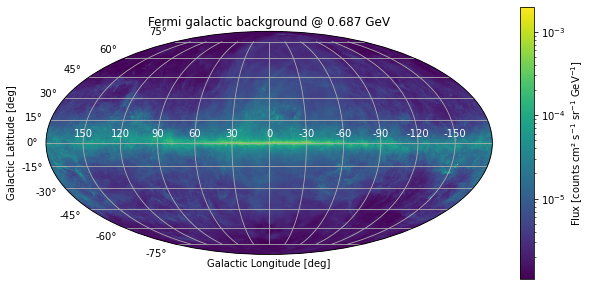

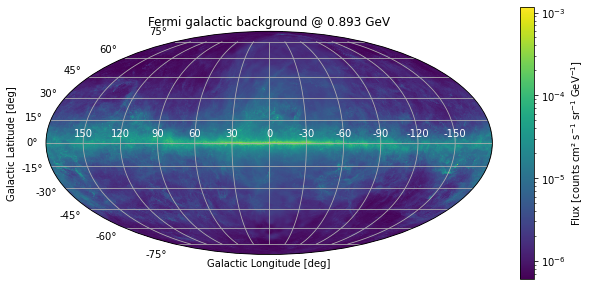

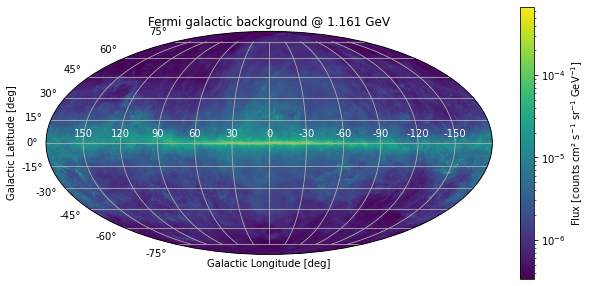

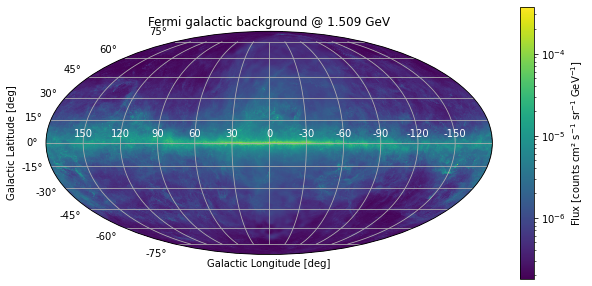

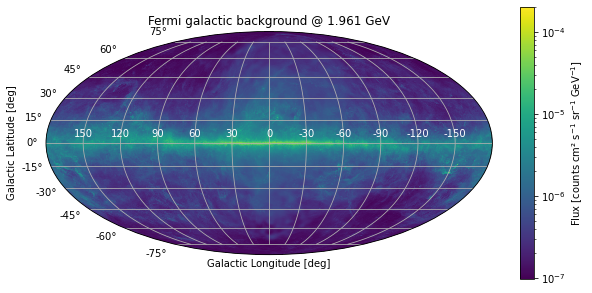

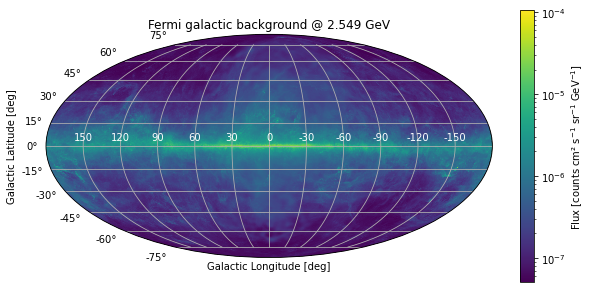

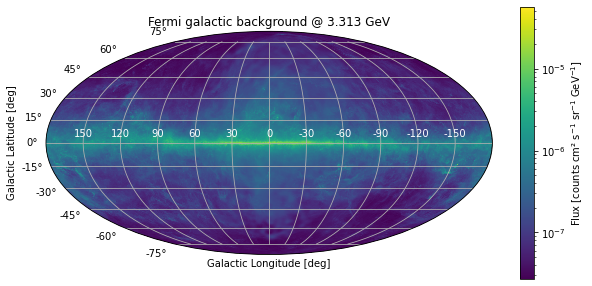

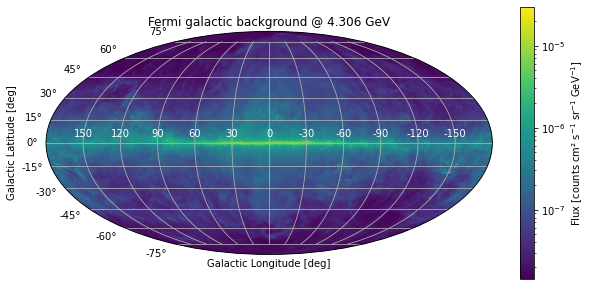

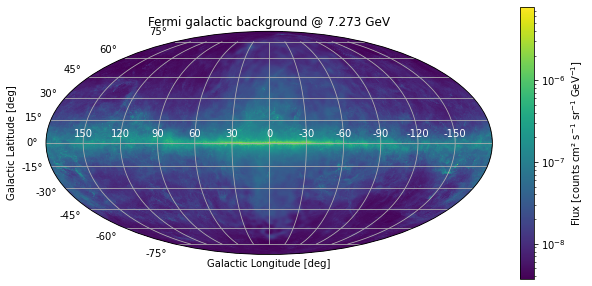

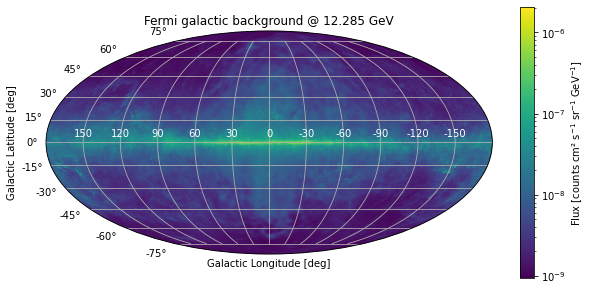

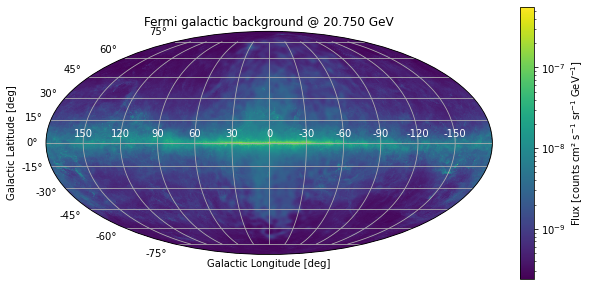

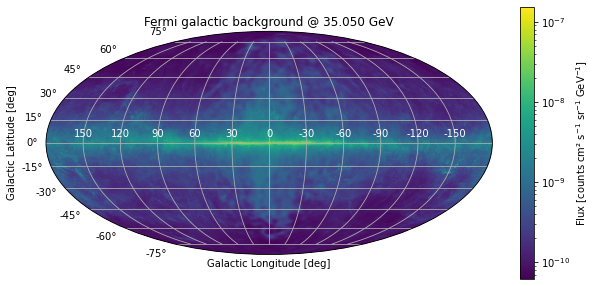

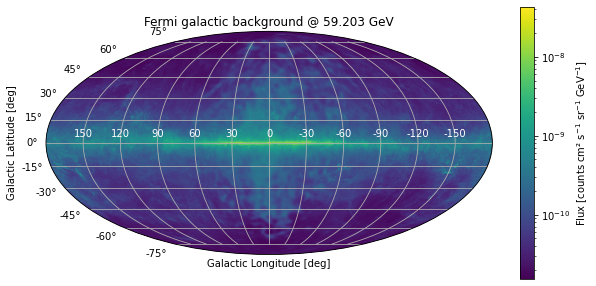

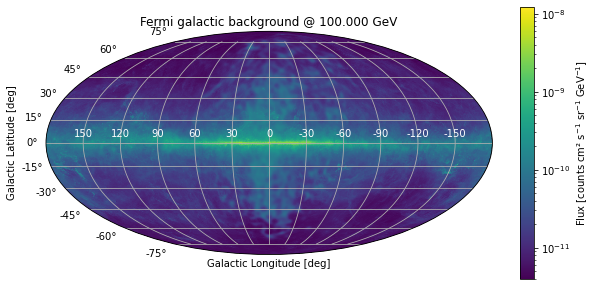

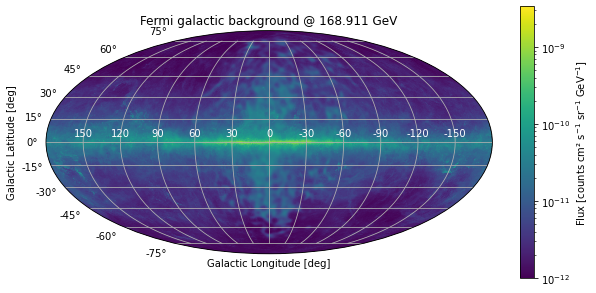

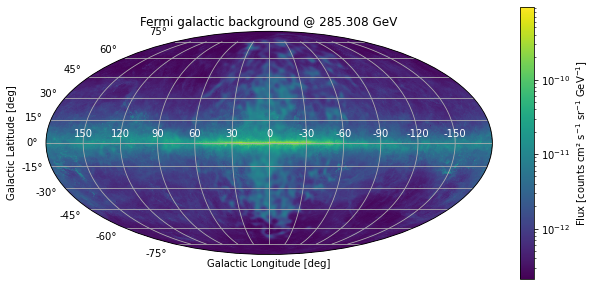

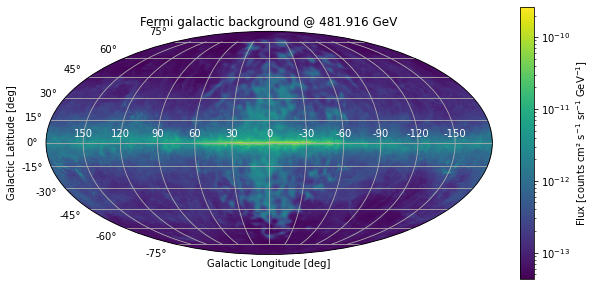

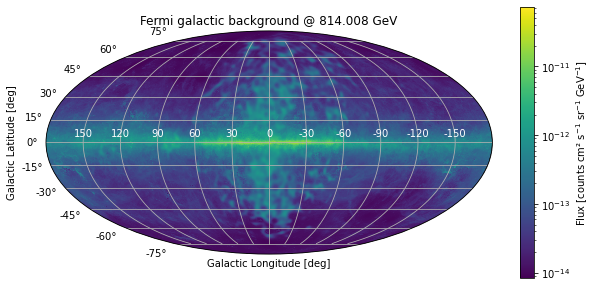

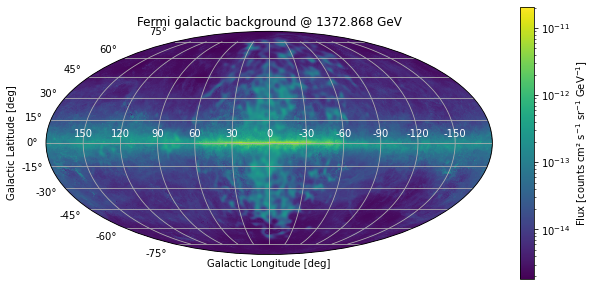

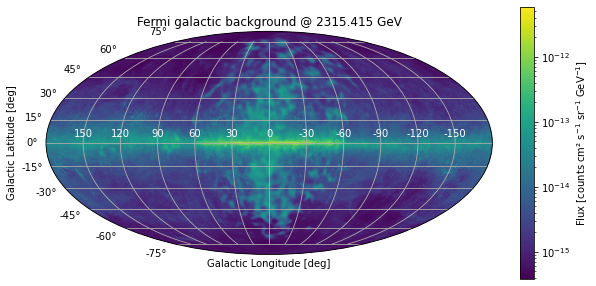

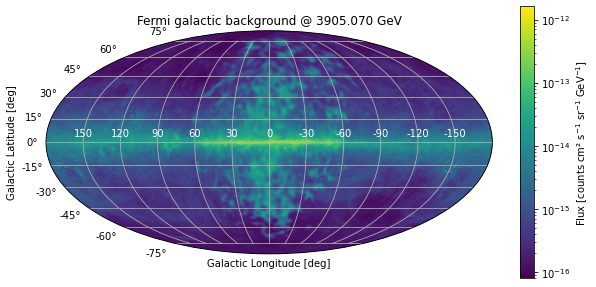

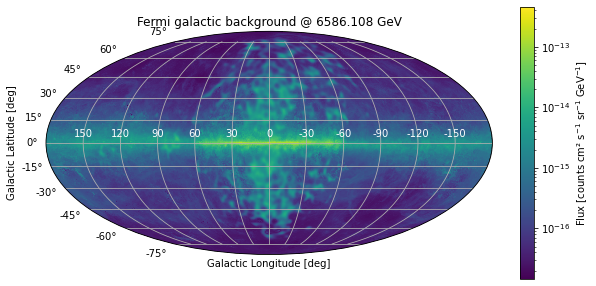

In [22]:
for e in energies_all :
    fig = plot_sky_slice(e, data_cube_extended, energies_all)
    fig.savefig(figPath + f"GIEM_{e:.3f}_GeV.png")
    